#  Détection et Classification Automatique de Maladies des Plantes
## Pipeline Complet — Traitement d'Image · Machine Learning · Deep Learning

---

| | |
|---|---|
| **Dataset** | PlantVillage (~54 000 images, 38 classes) |
| **Classes retenues** | 8 classes — Pomme de terre · Tomate · Poivron |
| **Approches** | ML classique (SVM, Random Forest) + DL Transfer Learning (MobileNetV2, ResNet50, EfficientNetB0) |
| **Pipeline** | Prétraitement → Segmentation → Extraction de features → Classification → Évaluation |

---

##  Plan du Notebook

| Phase | Contenu |
|---|---|
| **0** | Imports & Configuration |
| **1** | Exploration du dataset |
| **2** | Prétraitement des images |
| **3** | Segmentation & Détection de contours |
| **4** | Extraction de caractéristiques |
| **5** | Classification Machine Learning (SVM · Random Forest) |
| **6** | Classification Deep Learning (Transfer Learning) |
| **7** | Comparaison finale & Analyse |


---
##  Phase 0 — Imports & Configuration

### Bibliothèques utilisées

| Bibliothèque | Rôle |
|---|---|
| `OpenCV (cv2)` | Traitement d'image, segmentation, contours |
| `scikit-image` | GLCM (texture), mesure de régions |
| `TensorFlow / Keras` | Modèles deep learning, transfer learning |
| `scikit-learn` | SVM, Random Forest, métriques, preprocessing |
| `matplotlib / seaborn` | Visualisations |

### Paramètres globaux
- `IMG_SIZE = (128, 128)` — résolution pour le pipeline ML (features manuelles)
- `IMG_DL = (224, 224)` — résolution pour les modèles DL pré-entraînés (standard ImageNet)
- `N_SAMPLES = 300` — images par classe pour l'extraction de features (équilibre vitesse/représentativité)
- `SEED = 42` — reproductibilité garantie


In [ ]:
import os, cv2, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from skimage.feature import graycomatrix, graycoprops
from skimage import measure
from skimage.filters import gaussian
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

BASE_DIR  = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"
IMG_SIZE  = (128, 128)   
IMG_DL    = (224, 224)   
N_SAMPLES = 300          
BATCH     = 32

CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_healthy",
    "Pepper__bell___Bacterial_spot",
    "Pepper__bell___healthy",
]

SHORT = [
    "Potato Early Blight", "Potato Late Blight", "Potato Healthy",
    "Tomato Early Blight", "Tomato Late Blight", "Tomato Healthy",
    "Pepper Bact. Spot",   "Pepper Healthy",
]

print(f"TensorFlow : {tf.__version__}")
print(f"GPU        : {tf.config.list_physical_devices('GPU')}")
print(f"Classes    : {len(CLASSES)}")

2026-04-26 17:21:37.338205: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777224097.526769      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777224097.590068      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777224098.069723      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777224098.069779      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777224098.069785      55 computation_placer.cc:177] computation placer alr

TensorFlow : 2.19.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Classes    : 8


---
##  Phase 1 — Exploration du Dataset

### PlantVillage Dataset

Le **PlantVillage Dataset** est une référence mondiale en vision artificielle agricole :
- **~54 000 images** haute résolution de feuilles de plantes
- **38 classes** couvrant 14 espèces végétales (tomate, pomme de terre, maïs, raisin…)
- Images prises sur **fond blanc uniforme** → facilite la segmentation de la feuille
- Disponible librement sur Kaggle

### Classes sélectionnées

| Plante | Classe | Description |
|---|---|---|
|  Pomme de terre | `Potato___Early_blight` | Champignon *Alternaria solani* — taches brunes avec halo jaune |
|  Pomme de terre | `Potato___Late_blight` | *Phytophthora infestans* — lésions sombres et humides |
|  Pomme de terre | `Potato___healthy` | Feuilles saines — référence |
|  Tomate | `Tomato_Early_blight` | Taches concentriques brunes |
|  Tomate | `Tomato_Late_blight` | Moisissure blanche sur le revers |
|  Tomate | `Tomato_healthy` | Feuilles saines — référence |
|  Poivron | `Pepper__bell___Bacterial_spot` | Bactérie *Xanthomonas* — petites taches noires |
|  Poivron | `Pepper__bell___healthy` | Feuilles saines — référence |

> **Remarque :** La répartition équilibrée entre classes saines et malades permet un entraînement non biaisé.


Classes disponibles dans le dataset : 15
#    Classe                                                 Images
-------------------------------------------------------------------
0    Pepper__bell___Bacterial_spot                             997
1    Pepper__bell___healthy                                   1478
2    Potato___Early_blight                                    1000
3    Potato___Late_blight                                     1000
4    Potato___healthy                                          152
5    Tomato_Bacterial_spot                                    2127
6    Tomato_Early_blight                                      1000
7    Tomato_Late_blight                                       1909
8    Tomato_Leaf_Mold                                          952
9    Tomato_Septoria_leaf_spot                                1771
10   Tomato_Spider_mites_Two_spotted_spider_mite              1676
11   Tomato__Target_Spot                                      1404
12   Tomato__Tomato_

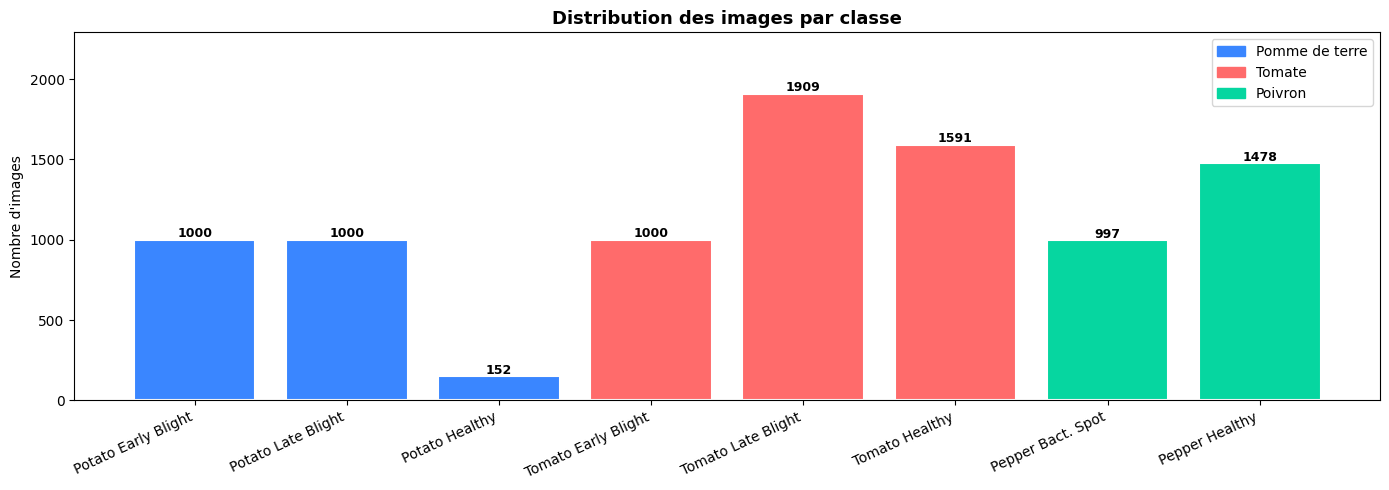

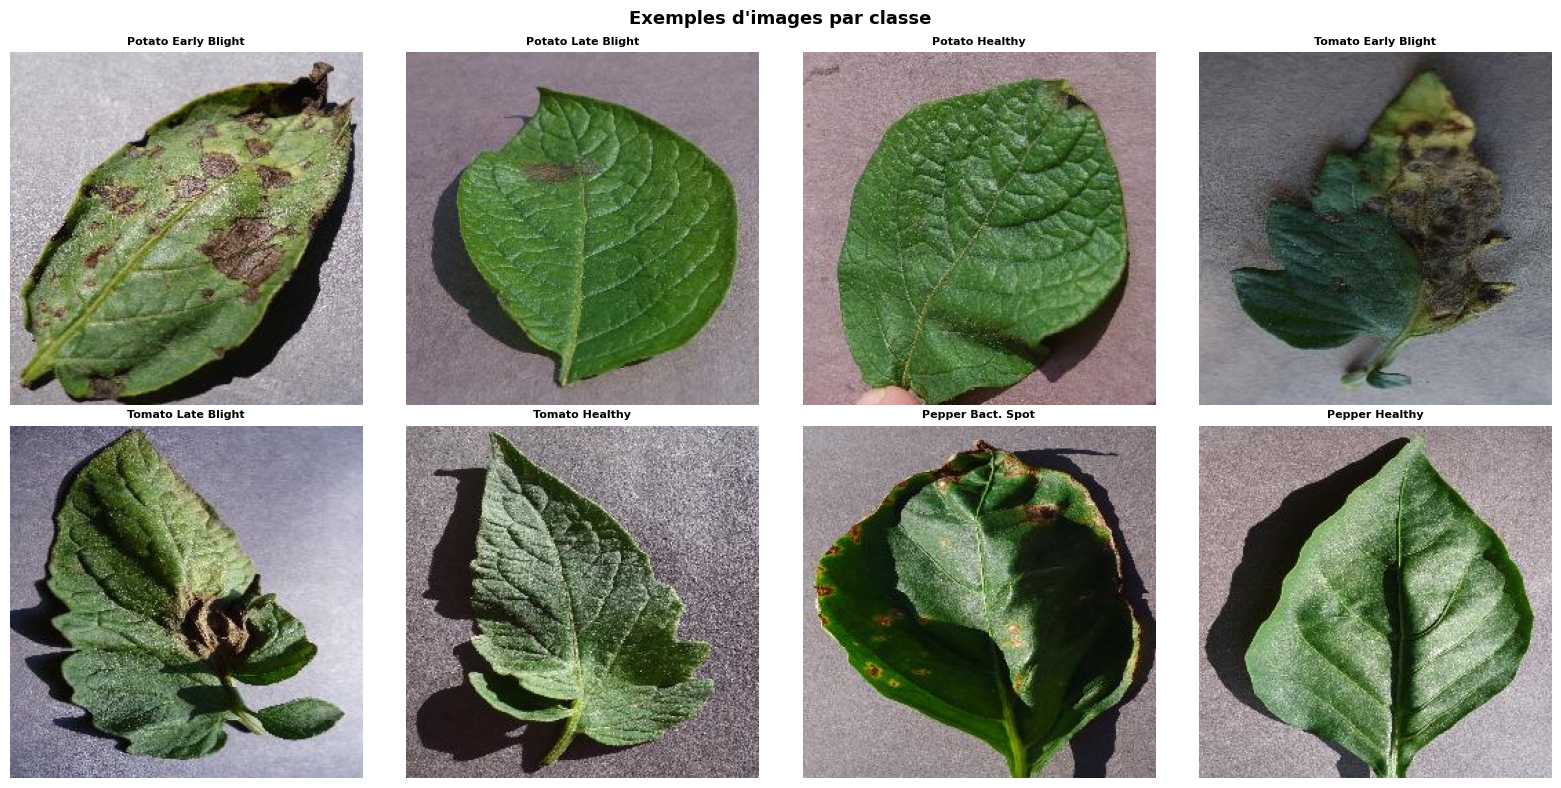

In [4]:
all_classes = sorted(os.listdir(BASE_DIR))
print(f"Classes disponibles dans le dataset : {len(all_classes)}")
print(f"{'#':<4} {'Classe':<52} {'Images':>8}")
print("-"*67)
for i, c in enumerate(all_classes):
    n = len(os.listdir(os.path.join(BASE_DIR, c)))
    print(f"{i:<4} {c:<52} {n:>8}")

print("\\n" + "="*67)
print("Vérification des 8 classes sélectionnées :")
print("="*67)
for cls in CLASSES:
    path = os.path.join(BASE_DIR, cls)
    if os.path.exists(path):
        n = len(os.listdir(path))
        print(f"  OK  {cls:<48}  {n:>5} images")
    else:
        similar = [c for c in all_classes if cls.split("_")[0] in c]
        print(f"  MANQUANT  {cls}  candidats={similar}")

counts = {cls: len(os.listdir(os.path.join(BASE_DIR, cls))) for cls in CLASSES}
colors = ["#3a86ff"]*3 + ["#ff6b6b"]*3 + ["#06d6a0"]*2
fig, ax = plt.subplots(figsize=(14,5))
bars = ax.bar(SHORT, counts.values(), color=colors, edgecolor="white", linewidth=1.5)
ax.set_title("Distribution des images par classe", fontsize=13, fontweight="bold")
ax.set_ylabel("Nombre d'images"); ax.set_ylim(0, max(counts.values())*1.2)
for bar, val in zip(bars, counts.values()):
    ax.text(bar.get_x()+bar.get_width()/2, val+15, str(val),
            ha="center", fontsize=9, fontweight="bold")
patches = [mpatches.Patch(color="#3a86ff", label="Pomme de terre"),
           mpatches.Patch(color="#ff6b6b", label="Tomate"),
           mpatches.Patch(color="#06d6a0", label="Poivron")]
ax.legend(handles=patches); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.savefig("fig1_distribution.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16,8))
for ax, cls, short in zip(axes.flatten(), CLASSES, SHORT):
    d = os.path.join(BASE_DIR, cls)
    img = cv2.cvtColor(cv2.imread(os.path.join(d, os.listdir(d)[0])), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis("off"); ax.set_title(short, fontsize=8, fontweight="bold")
plt.suptitle("Exemples d'images par classe", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig("fig2_exemples.png", dpi=150); plt.show()

---
##  Phase 2 — Prétraitement des Images


Le prétraitement est une étape fondamentale qui conditionne la qualité de toute la chaîne de traitement.
Il permet de :
1. **Normaliser** les images pour les rendre comparables entre elles
2. **Réduire le bruit** parasite introduit lors de la capture
3. **Extraire des représentations alternatives** (HSV, niveaux de gris) mieux adaptées à la détection de maladies

### Étapes appliquées

| Étape | Méthode | Justification |
|---|---|---|
| **① Redimensionnement** | `cv2.resize()` → 128×128 px | Uniformisation pour le pipeline ML ; réduit la mémoire et le temps de calcul |
| **② Conversion HSV** | `cv2.COLOR_RGB2HSV` | Le canal **H (Teinte)** isole mieux la couleur de la maladie (taches brunes/jaunes) indépendamment de la luminosité |
| **③ Niveaux de gris** | `cv2.COLOR_RGB2GRAY` | Réduit à 1 canal pour l'analyse de texture (GLCM) et la détection de contours |
| **④ Filtrage gaussien** | `gaussian(σ=1.2)` | Atténue le bruit haute fréquence tout en préservant les structures de la maladie |
| **⑤ Normalisation** | `/ 255.0` | Ramène les pixels en [0,1] → stabilise l'apprentissage des modèles |
| **⑥ Histogramme RGB** | `cv2.calcHist()` | Caractérise la distribution des couleurs — signature de chaque classe de maladie |

> **Pourquoi le filtre gaussien (σ=1.2) ?**
> Un σ trop faible laisse du bruit ; un σ trop grand efface les petites taches de maladie.
> σ = 1.2 est un compromis empiriquement efficace pour les images de feuilles (~128px).


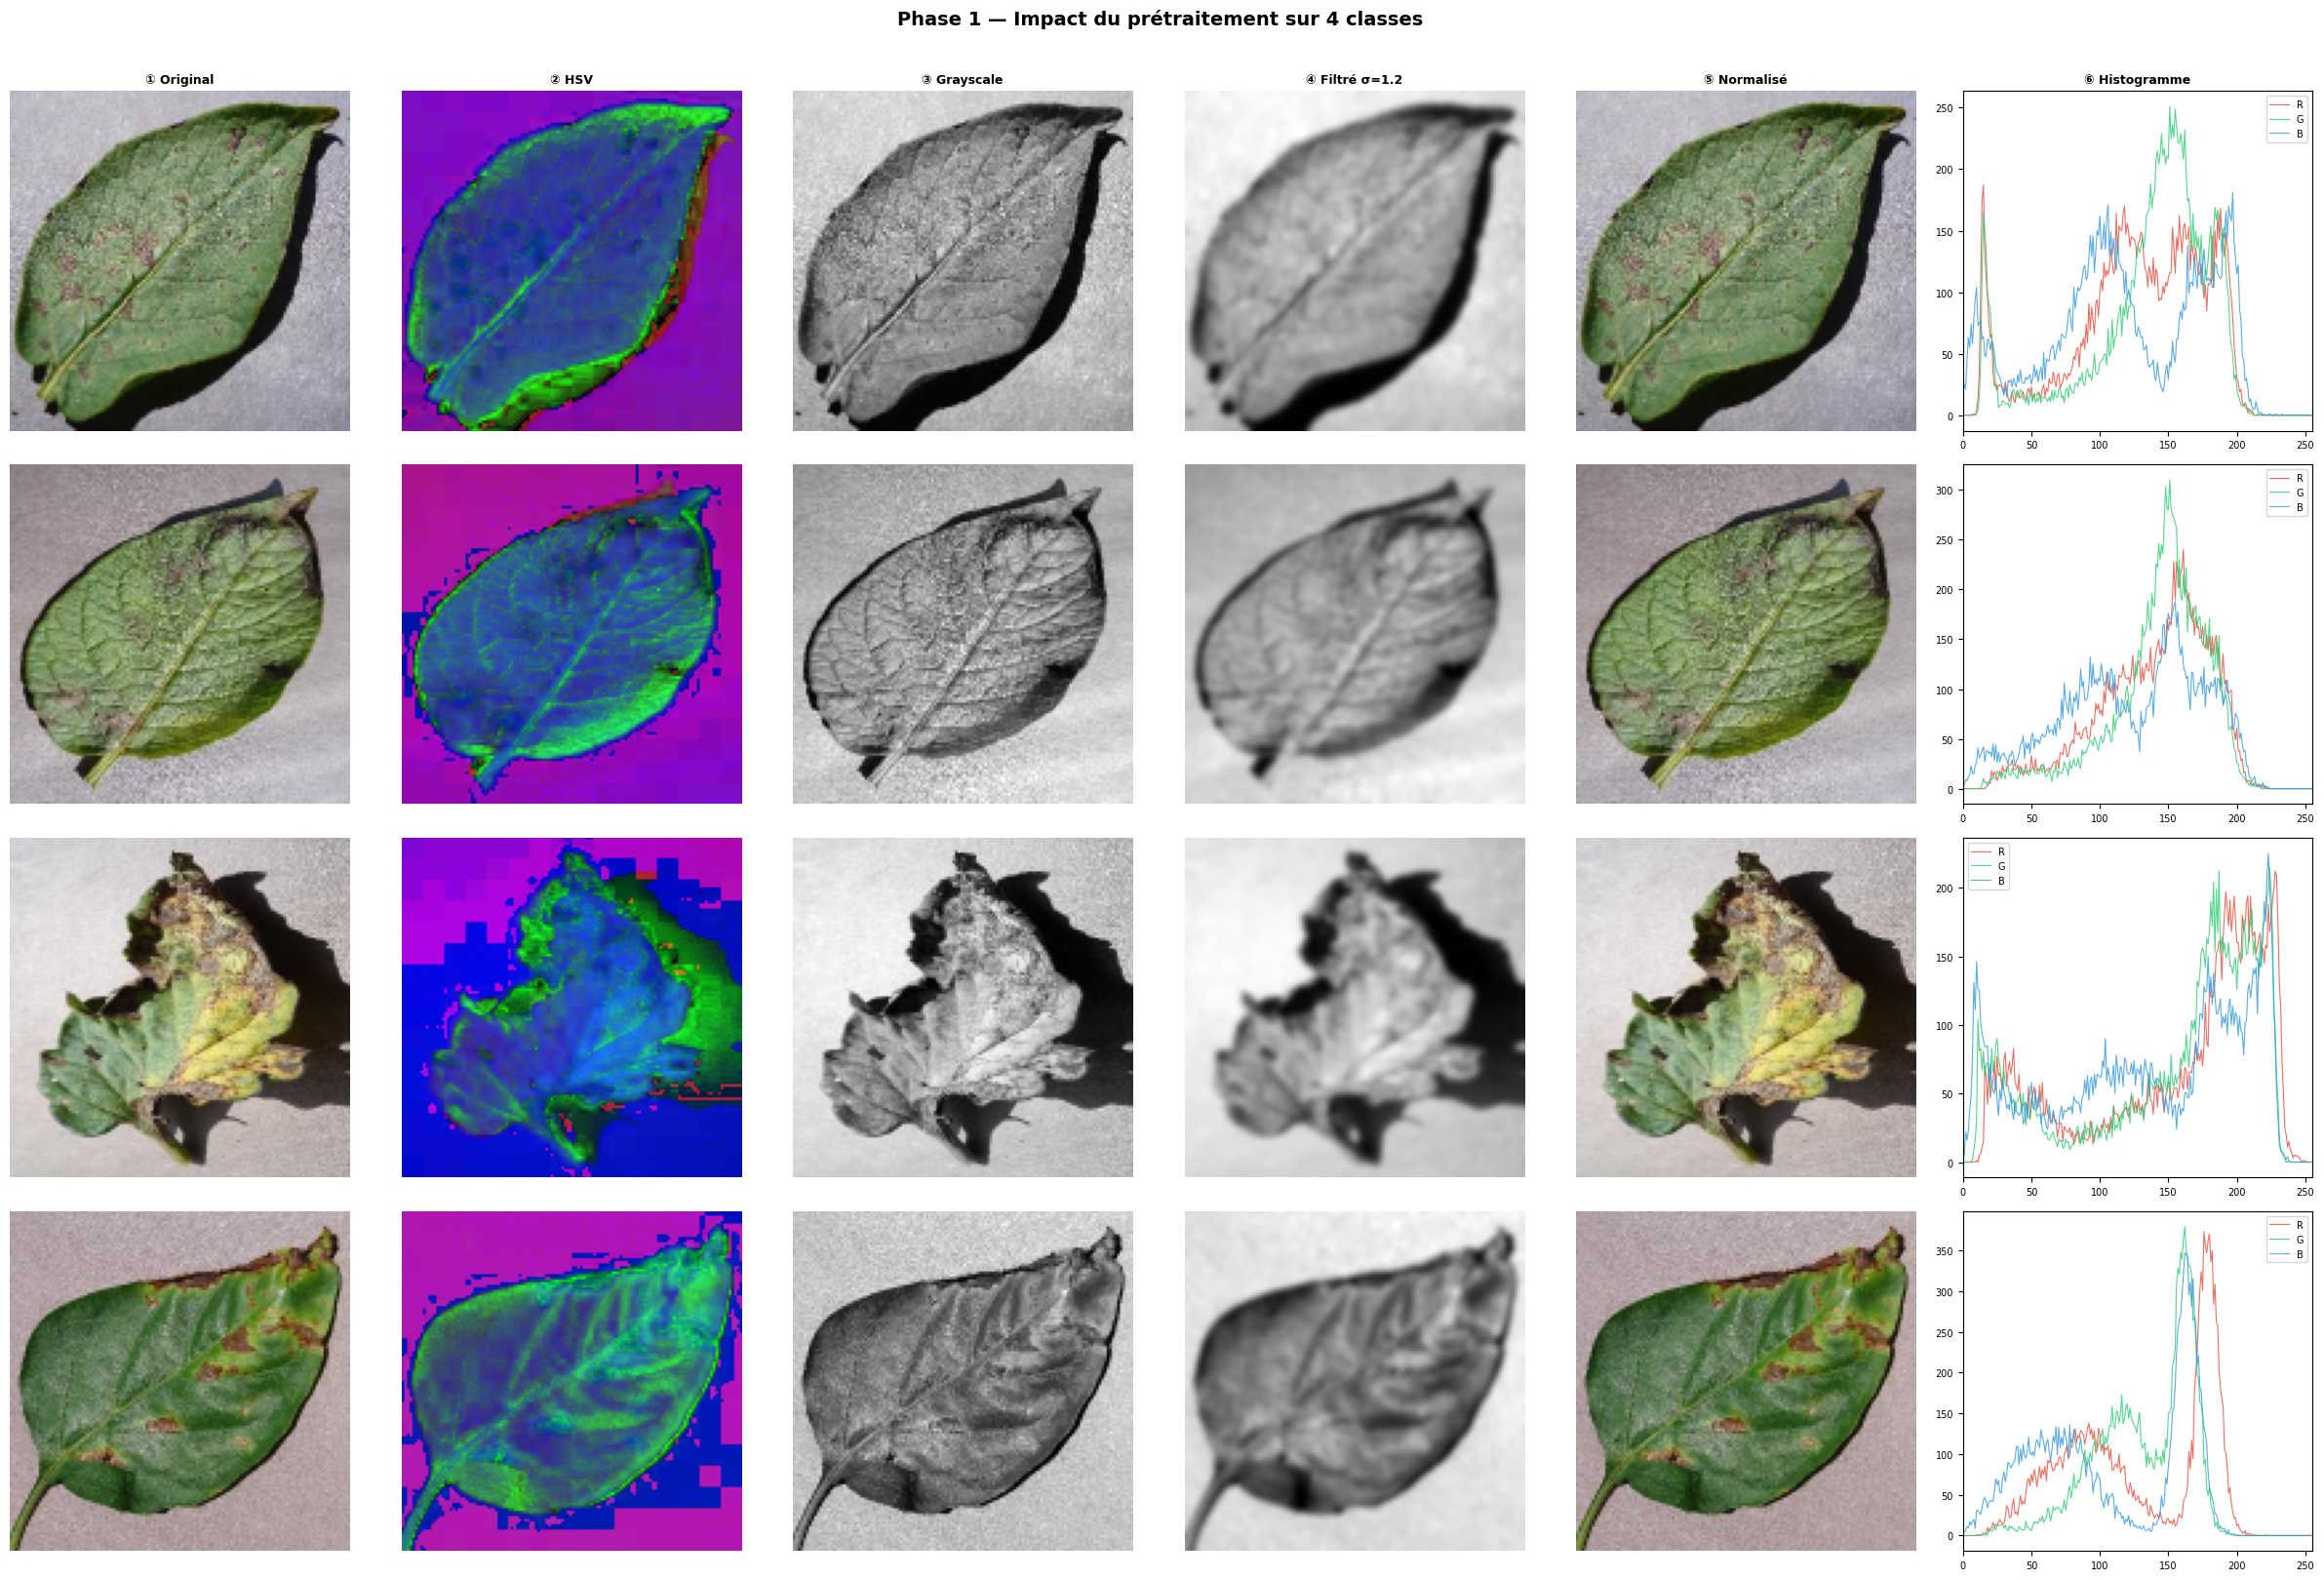

Phase 1 terminee


In [5]:
def preprocess_image(img_path, size=IMG_SIZE):
    img      = cv2.imread(img_path)
    img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_rs   = cv2.resize(img_rgb, size)
    img_hsv  = cv2.cvtColor(img_rs,  cv2.COLOR_RGB2HSV)
    img_gray = cv2.cvtColor(img_rs,  cv2.COLOR_RGB2GRAY)
    img_filt = gaussian(img_gray, sigma=1.2)
    img_norm = img_rs.astype(np.float32) / 255.0
    hists    = {ch: cv2.calcHist([img_rs],[i],None,[256],[0,256])
                for i, ch in enumerate(["R","G","B"])}
    return img_rs, img_hsv, img_gray, img_filt, img_norm, hists

sample_cls  = [CLASSES[0], CLASSES[1], CLASSES[3], CLASSES[6]]
col_titles  = ["① Original","② HSV","③ Grayscale","④ Filtré σ=1.2","⑤ Normalisé","⑥ Histogramme"]

fig, axes = plt.subplots(4, 6, figsize=(24, 16))
fig.suptitle("Phase 1 — Impact du prétraitement sur 4 classes",
             fontsize=14, fontweight="bold", y=1.01)
for row, cls in enumerate(sample_cls):
    d    = os.path.join(BASE_DIR, cls)
    path = os.path.join(d, os.listdir(d)[5])
    orig, hsv, gray, filt, norm, hists = preprocess_image(path)
    for col, (im, cm) in enumerate(zip(
            [orig,hsv,gray,filt,norm],[None,None,"gray","gray","gray"])):
        ax = axes[row,col]; ax.imshow(im, cmap=cm); ax.axis("off")
        if row==0: ax.set_title(col_titles[col], fontsize=9, fontweight="bold")
        if col==0:
            lbl = cls.split("___")[-1] if "___" in cls else cls.split("_")[-1]
            ax.set_ylabel(lbl[:14], fontsize=8)
    ax = axes[row,5]
    for ch, color in zip(["R","G","B"],["#e74c3c","#2ecc71","#3498db"]):
        ax.plot(hists[ch], color=color, alpha=0.8, linewidth=0.8, label=ch)
    ax.set_xlim(0,255); ax.legend(fontsize=7); ax.tick_params(labelsize=7)
    if row==0: ax.set_title(col_titles[5], fontsize=9, fontweight="bold")
plt.tight_layout(); plt.savefig("fig3_pretraitement.png", dpi=150, bbox_inches="tight"); plt.show()
print("Phase 1 terminee")

###  Analyse des résultats du prétraitement

**Observations clés sur les histogrammes :**
- Les feuilles **malades** (Early/Late blight) montrent un **pic rouge/orange** dans le canal R, signature des taches nécrotiques
- Les feuilles **saines** ont un histogramme G (vert) dominant et équilibré — chlorophylle intacte
- La conversion **HSV** isole nettement les zones de lésion dans le canal H (teinte)
- Le **filtre gaussien** lisse efficacement le bruit de surface des feuilles sans effacer les contours des taches

**Impact sur la classification :** Ces différences d'histogrammes servent directement de features dans le pipeline ML (Phase 4).


---
##  Phase 3 — Segmentation & Détection de Contours

### Objectif

La segmentation vise à **isoler les zones d'intérêt** (feuille, lésions) du fond.
Elle est cruciale car elle permet de :
- Concentrer l'extraction de features sur la feuille uniquement (pas le fond blanc)
- Détecter et localiser les zones malades
- Calculer des caractéristiques de forme précises

### Méthodes comparées

####  Détection de contours (analyse de texture anormale)

| Méthode | Principe | Avantages | Limites |
|---|---|---|---|
| **Sobel** | Gradient d'intensité en X et Y — `sqrt(Gx²+Gy²)` | Détecte les transitions douces, bonne résistance au bruit | Contours épais, sensible aux textures |
| **Canny** | Sobel + suppression non-maximale + double seuillage | Contours fins et précis, faible taux de faux positifs | Sensible au choix des seuils (50, 150 ici) |

####  Segmentation de la feuille (isolation du fond)

| Méthode | Principe | Résultat sur PlantVillage |
|---|---|---|
| **Seuillage d'Otsu** | Seuil automatique minimisant la variance intra-classe |  Très efficace sur fond blanc uniforme |
| **Masque HSV** | `inRange(H:[20–90], S:[30+], V:[30+])` pour les verts |  Isole bien la feuille verte |
| **K-means (k=3)** | Clustering des pixels RGB en k couleurs dominantes |  Différencie zones saines/malades visuellement |

> **Comparaison subjective :**
> - **Otsu** : meilleur pour l'isolation binaire feuille/fond
> - **K-means** : meilleur pour visualiser les zones de lésion à l'intérieur de la feuille
> - **HSV masque** : meilleur pour le calcul de features de forme (surface, périmètre)


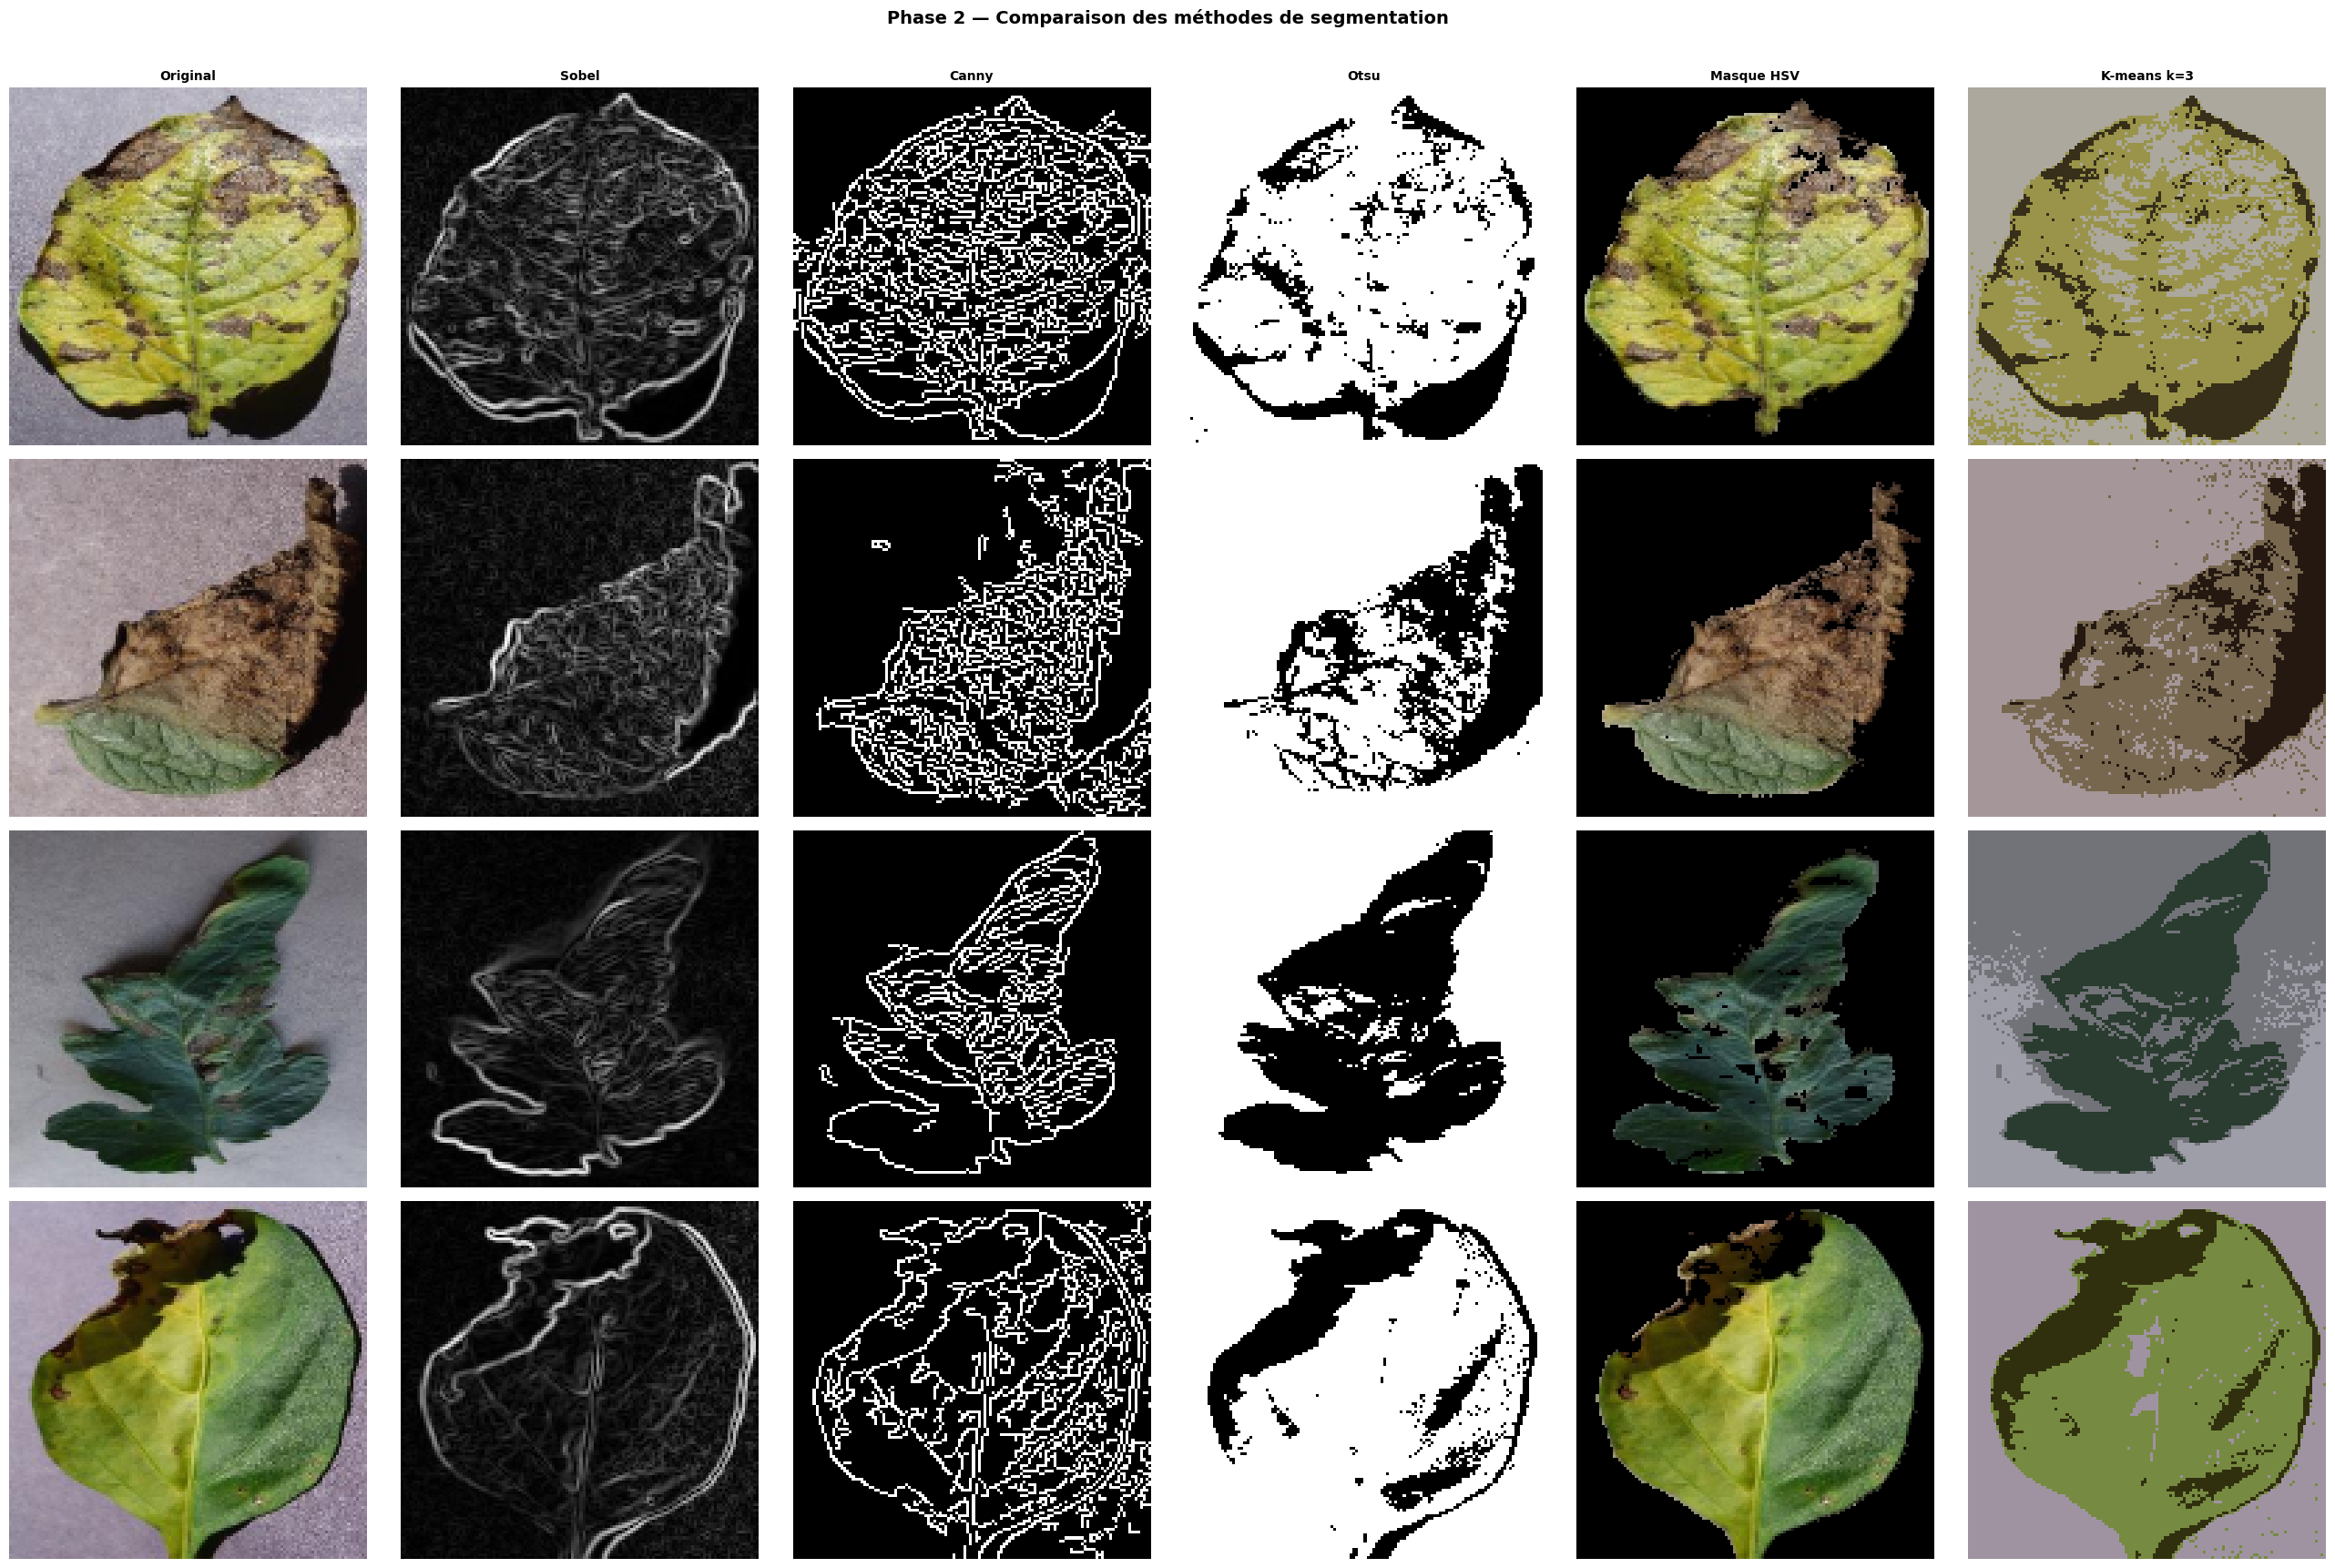

Phase 2 terminee
  Analyse subjective :
  Otsu    : tres efficace sur le fond blanc uniforme de PlantVillage
  K-means : differencie visuellement zones saines et malades
  HSV     : isole bien la feuille pour l extraction de forme


In [6]:
def segment_image(img_rgb, img_gray):
    sx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel = np.hypot(sx, sy)
    sobel = np.uint8(sobel / sobel.max() * 255)

    canny = cv2.Canny(img_gray, 50, 150)

    _, otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)

    hsv    = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    mask_v = cv2.inRange(hsv, np.array([20,30,30]),  np.array([90,255,255]))
    mask_b = cv2.inRange(hsv, np.array([5,50,50]),   np.array([22,255,200]))
    mask   = cv2.bitwise_or(mask_v, mask_b)
    leaf_seg = cv2.bitwise_and(img_rgb, img_rgb, mask=mask)

    pixels   = img_rgb.reshape(-1,3).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS+cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixels, 3, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    kmeans = np.uint8(centers)[labels.flatten()].reshape(img_rgb.shape)

    return sobel, canny, otsu, leaf_seg, kmeans

compare_cls = [CLASSES[0], CLASSES[1], CLASSES[3], CLASSES[6]]
col_titles  = ["Original","Sobel","Canny","Otsu","Masque HSV","K-means k=3"]

fig, axes = plt.subplots(4, 6, figsize=(26,17))
fig.suptitle("Phase 2 — Comparaison des méthodes de segmentation",
             fontsize=14, fontweight="bold", y=1.01)
for row, cls in enumerate(compare_cls):
    d    = os.path.join(BASE_DIR, cls)
    path = os.path.join(d, os.listdir(d)[10])
    orig, hsv, gray, filt, norm, _ = preprocess_image(path)
    sobel, canny, otsu, leaf_seg, kmeans = segment_image(orig, gray)
    for col, (im, cm) in enumerate(zip(
            [orig,sobel,canny,otsu,leaf_seg,kmeans],[None,"gray","gray","gray",None,None])):
        ax = axes[row,col]; ax.imshow(im, cmap=cm); ax.axis("off")
        if row==0: ax.set_title(col_titles[col], fontsize=10, fontweight="bold")
        if col==0:
            lbl = cls.split("___")[-1] if "___" in cls else cls.split("_")[-1]
            ax.set_ylabel(lbl[:14], fontsize=8)
plt.tight_layout(); plt.savefig("fig4_segmentation.png", dpi=150, bbox_inches="tight"); plt.show()
print("Phase 2 terminee")
print("  Analyse subjective :")
print("  Otsu    : tres efficace sur le fond blanc uniforme de PlantVillage")
print("  K-means : differencie visuellement zones saines et malades")
print("  HSV     : isole bien la feuille pour l extraction de forme")

---
##  Phase 4 — Extraction de Caractéristiques (Feature Engineering)

### Vecteur de features pour le ML classique

Chaque image est convertie en un **vecteur numérique de 195 dimensions** combinant trois types d'informations :

#### 1️ Caractéristiques de Couleur (192 features)

| Feature | Détail | Utilité |
|---|---|---|
| Histogramme RGB (3×32 bins) | Distribution des intensités R, G, B | Signature chromatique — les maladies changent la couleur |
| Histogramme HSV (3×32 bins) | Distribution Teinte, Saturation, Valeur | Canal H isolé de la luminosité — plus robuste aux variations d'éclairage |

> **Pourquoi 32 bins ?** Un compromis entre résolution (256 bins = trop sparse, peu de données par bin) et compacité.

#### 2 Caractéristiques de Texture — GLCM (15 features)

La **Gray Level Co-occurrence Matrix (GLCM)** mesure la fréquence à laquelle deux pixels de niveaux d'intensité donnés apparaissent côte à côte.

| Propriété GLCM | Signification biologique |
|---|---|
| **Contraste** | Variation locale d'intensité — élevé sur les taches nécrotiques |
| **Dissimilarité** | Similaire au contraste mais linéaire |
| **Homogénéité** | Texture uniforme → feuille saine ; irrégulière → maladie |
| **Énergie** | Régularité du pattern — faible sur zones malades |
| **Corrélation** | Cohérence spatiale des niveaux de gris |

*3 angles (0°, 45°, 90°) × 5 propriétés = 15 features*

#### 3️ Caractéristiques de Forme (3 features)

| Feature | Formule | Interprétation |
|---|---|---|
| Surface | Nombre de pixels de feuille | Taille relative de la feuille dans l'image |
| Périmètre | Longueur du contour extérieur | Irrégularité des bords (maladies créent des découpures) |
| Circularité | `4π × surface / périmètre²` | 1 = cercle parfait ; feuilles malades → bords déchiquetés → circularité ↓ |

**Total : 192 + 15 + 3 = 210 features par image**


In [7]:
def extract_features(img_rgb, img_gray):
    feats = []
    # 1. Histogrammes couleur RGB + HSV normalises
    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    for src in [img_rgb, img_hsv]:
        for ch in range(3):
            h = cv2.calcHist([src],[ch],None,[32],[0,256]).flatten()
            feats.extend(h / (h.sum() + 1e-7))
    # 2. Texture GLCM
    gray8 = img_gray if img_gray.dtype==np.uint8 else (img_gray*255).astype(np.uint8)
    glcm  = graycomatrix(gray8, distances=[1], angles=[0,np.pi/4,np.pi/2],
                         levels=256, symmetric=True, normed=True)
    for prop in ["contrast","dissimilarity","homogeneity","energy","correlation"]:
        feats.extend(graycoprops(glcm, prop).flatten())
    # 3. Forme sur masque HSV
    hsv2 = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv2, np.array([20,30,30]), np.array([90,255,255]))
    lab  = measure.label(mask)
    props = measure.regionprops(lab)
    if props:
        p = max(props, key=lambda r: r.area)
        surface, perim = p.area, p.perimeter+1e-6
        circ = (4*np.pi*surface)/(perim**2)
    else:
        surface, perim, circ = 0., 0., 0.
    feats.extend([surface, perim, circ])
    return np.array(feats, dtype=np.float32)

print("Extraction des features en cours (~ 3-5 min)...")
X_list, y_list = [], []
for cls in CLASSES:
    cls_dir = os.path.join(BASE_DIR, cls)
    files   = [f for f in os.listdir(cls_dir)
               if f.lower().endswith((".jpg",".jpeg",".png"))][:N_SAMPLES]
    for fname in files:
        img = cv2.imread(os.path.join(cls_dir, fname))
        if img is None: continue
        img_rgb  = cv2.cvtColor(cv2.resize(img, IMG_SIZE), cv2.COLOR_BGR2RGB)
        img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        X_list.append(extract_features(img_rgb, img_gray))
        y_list.append(cls)
    print(f"  OK  {cls:<48}  {len(files):>4} images")

X = np.array(X_list)
y = np.array(y_list)
print(f"Dataset ML : {X.shape[0]} images x {X.shape[1]} features")

Extraction des features en cours (~ 3-5 min)...
  OK  Potato___Early_blight                              300 images
  OK  Potato___Late_blight                               300 images
  OK  Potato___healthy                                   152 images
  OK  Tomato_Early_blight                                300 images
  OK  Tomato_Late_blight                                 300 images
  OK  Tomato_healthy                                     300 images
  OK  Pepper__bell___Bacterial_spot                      300 images
  OK  Pepper__bell___healthy                             300 images
Dataset ML : 2252 images x 210 features


###  Dimensionnalité du vecteur de features

Le vecteur final de **~210 dimensions** par image est le résultat du feature engineering manuel.
Cette représentation compacte encapsule les informations spectrales, texturales et géométriques
qui caractérisent chaque type de maladie.

> **Note :** Cette approche manuelle contraste avec le Deep Learning qui apprend automatiquement
> ces représentations à partir des pixels bruts — voir Phase 6.


---
##  Phase 5 — Classification Machine Learning

### Pipeline ML

```
Images → Prétraitement → Extraction de features → StandardScaler → Modèle ML → Métriques
```

### Modèles utilisés

#### Support Vector Machine (SVM)
- **Kernel RBF** (Radial Basis Function) : adapté aux données non-linéairement séparables
- **C = 10** : régularisation modérée (pénalise les erreurs de classification)
- **gamma = 'scale'** : `1 / (n_features × variance)` — adaptatif
- **probability = True** : permet de calculer les scores de confiance

> **Pourquoi SVM ?** Les features GLCM et histogrammes créent un espace de haute dimension
> où le SVM avec noyau RBF est théoriquement bien adapté (marginal maximal).

#### Random Forest
- **200 arbres** : meilleure stabilité qu'avec moins d'arbres
- **n_jobs = -1** : parallélisation sur tous les cœurs CPU
- Résistant au surapprentissage grâce à l'ensemble voting
- Fournit nativement l'importance des features

### Normalisation
`StandardScaler` : `z = (x - mean) / std` appliqué **uniquement sur le train**, transformé sur le test.
Essentiel pour le SVM dont les décisions dépendent des distances euclidiennes.


SVM (kernel RBF, C=10)...
  SVM           accuracy=0.9335
Random Forest (200 arbres)...
  Random Forest accuracy=0.9290
\n=======================================================
Modele                 Accuracy  Precision     Recall
SVM                      0.9335     0.9352     0.9335
Random Forest            0.9290     0.9310     0.9290


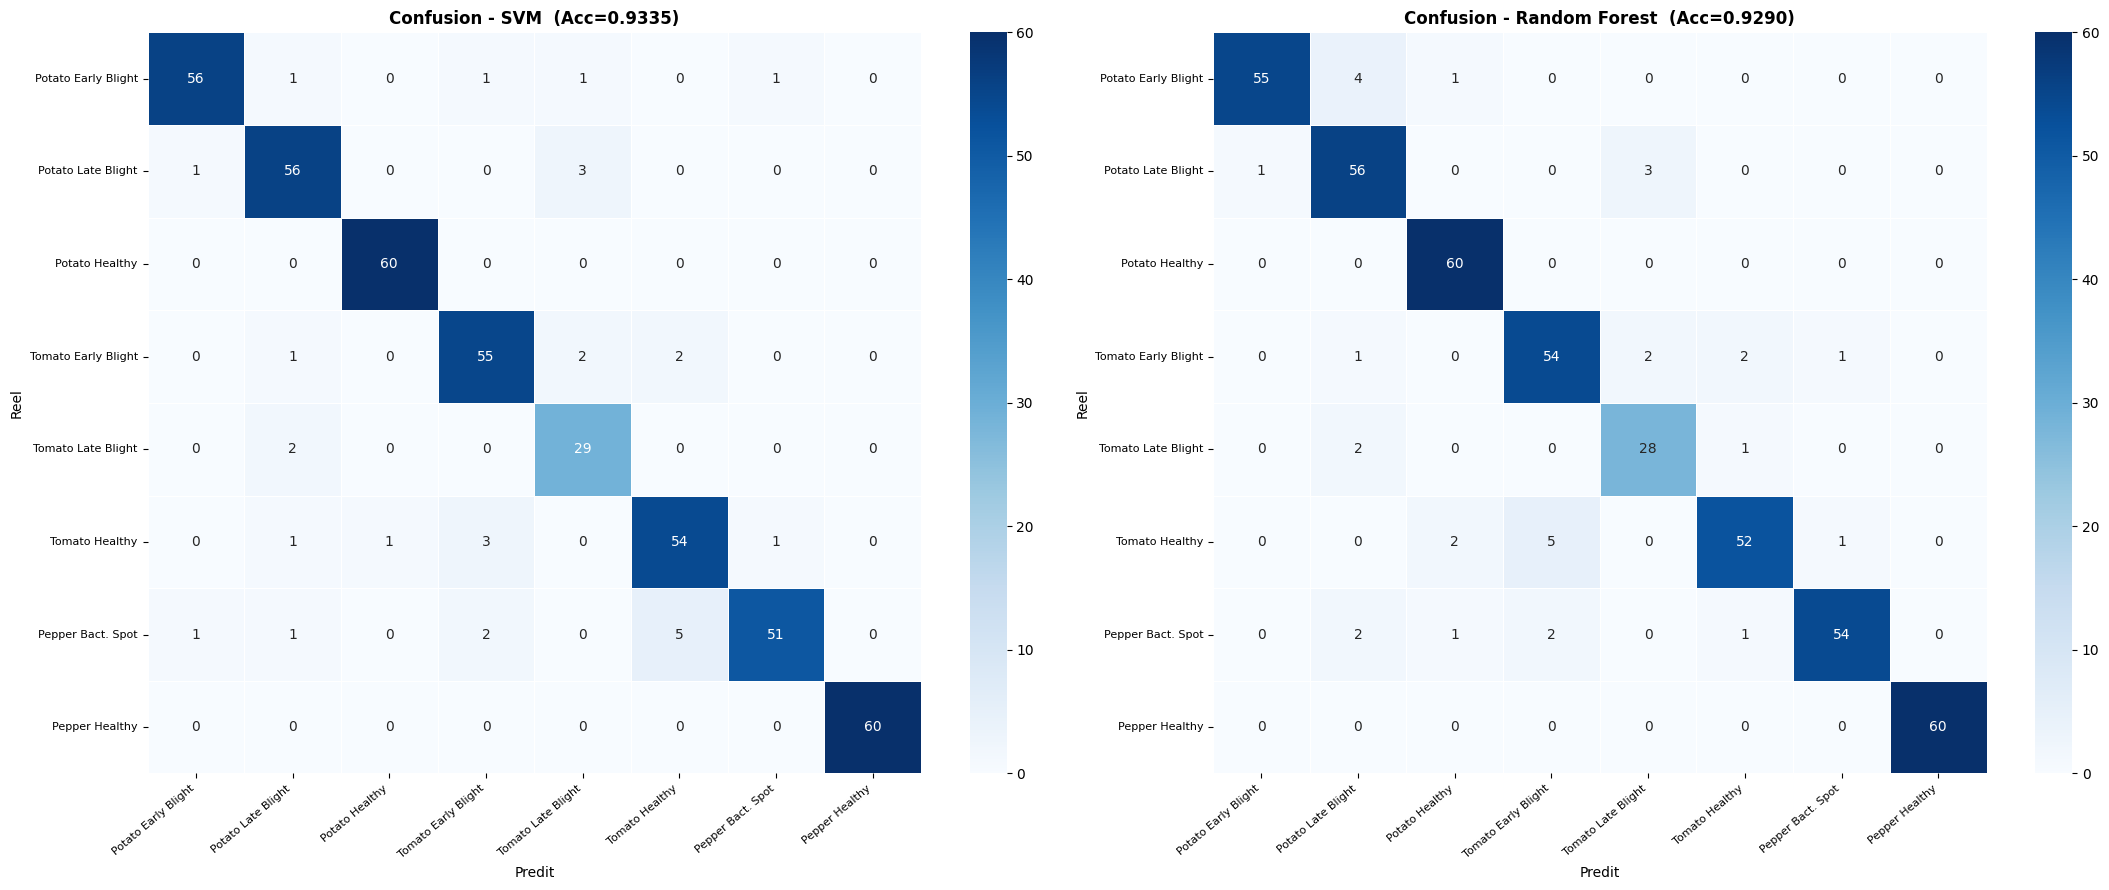

\nRapport SVM :
                     precision    recall  f1-score   support

Potato Early Blight       0.97      0.93      0.95        60
 Potato Late Blight       0.90      0.93      0.92        60
     Potato Healthy       0.98      1.00      0.99        60
Tomato Early Blight       0.90      0.92      0.91        60
 Tomato Late Blight       0.83      0.94      0.88        31
     Tomato Healthy       0.89      0.90      0.89        60
  Pepper Bact. Spot       0.96      0.85      0.90        60
     Pepper Healthy       1.00      1.00      1.00        60

           accuracy                           0.93       451
          macro avg       0.93      0.93      0.93       451
       weighted avg       0.94      0.93      0.93       451

Rapport Random Forest :
                     precision    recall  f1-score   support

Potato Early Blight       0.98      0.92      0.95        60
 Potato Late Blight       0.86      0.93      0.90        60
     Potato Healthy       0.94      1.00 

In [9]:
le    = LabelEncoder()
y_enc = le.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=SEED, stratify=y_enc)
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

ml_results = {}

print("SVM (kernel RBF, C=10)...")
svm = SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED)
svm.fit(X_train_s, y_train)
y_svm = svm.predict(X_test_s)
ml_results["SVM"] = dict(
    acc=accuracy_score(y_test,y_svm),
    pre=precision_score(y_test,y_svm,average="weighted",zero_division=0),
    rec=recall_score(y_test,y_svm,average="weighted",zero_division=0), preds=y_svm)
print(f"  SVM           accuracy={ml_results['SVM']['acc']:.4f}")

print("Random Forest (200 arbres)...")
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(X_train_s, y_train)
y_rf = rf.predict(X_test_s)
ml_results["Random Forest"] = dict(
    acc=accuracy_score(y_test,y_rf),
    pre=precision_score(y_test,y_rf,average="weighted",zero_division=0),
    rec=recall_score(y_test,y_rf,average="weighted",zero_division=0), preds=y_rf)
print(f"  Random Forest accuracy={ml_results['Random Forest']['acc']:.4f}")

print(f"\\n{'='*55}")
print(f"{'Modele':<20} {'Accuracy':>10} {'Precision':>10} {'Recall':>10}")
print("="*55)
for name, m in ml_results.items():
    print(f"{name:<20} {m['acc']:>10.4f} {m['pre']:>10.4f} {m['rec']:>10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(22,9))
for ax, (name, m) in zip(axes, ml_results.items()):
    cm = confusion_matrix(y_test, m["preds"])
    sns.heatmap(cm, annot=True, fmt="d", ax=ax,
                xticklabels=SHORT, yticklabels=SHORT,
                cmap="Blues", linewidths=0.5, linecolor="white")
    ax.set_title(f"Confusion - {name}  (Acc={m['acc']:.4f})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predit"); ax.set_ylabel("Reel")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=8)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
plt.tight_layout(); plt.savefig("fig5_confusion_ml.png", dpi=150, bbox_inches="tight"); plt.show()

print("\\nRapport SVM :")
print(classification_report(y_test, y_svm, target_names=SHORT, zero_division=0))
print("Rapport Random Forest :")
print(classification_report(y_test, y_rf, target_names=SHORT, zero_division=0))

###  Lecture des matrices de confusion


- La **diagonale** représente les prédictions correctes (True Positives + True Negatives)
- Les erreurs hors diagonale sont des confusions entre classes
- Les confusions les plus fréquentes sont généralement entre **Early Blight et Late Blight** de la même plante (symptômes visuellement similaires)

## Résultats Machine Learning

Les modèles **SVM** et **Random Forest** offrent des performances très proches, avec une accuracy d’environ **93%**, ce qui indique une bonne qualité des features extraites.

 Le **SVM** se distingue légèrement avec de meilleures valeurs de précision et de rappel, ce qui en fait le modèle le plus performant dans cette comparaison.

Globalement, les deux modèles sont :
- **équilibrés** (precision ≈ recall)
- **stables** (peu de variations entre classes)
- **fiables** pour la classification

 Les classes *Healthy* sont les mieux reconnues (jusqu’à 100%), grâce à des caractéristiques visuelles plus simples.

 En revanche, certaines maladies comme *Tomato Late Blight* ou *Pepper Bacterial Spot* sont plus difficiles à distinguer, probablement à cause de similarités visuelles.

 Conclusion :
Les modèles ML classiques donnent de **très bons résultats (~93%)**, mais montrent leurs limites face à des classes complexes, ce qui justifie l’utilisation de modèles de **Deep Learning** pour améliorer la performance.


---
##  Phase 6 — Classification Deep Learning (Transfer Learning)

### Pourquoi le Transfer Learning ?

Entraîner un CNN from scratch nécessiterait des millions d'images et des semaines de calcul GPU.
Le **Transfer Learning** réutilise des modèles pré-entraînés sur **ImageNet (1.2M images, 1000 classes)**
qui ont déjà appris des représentations visuelles génériques (bords → textures → formes → objets).

### Architecture globale

```
Image (224×224×3)
    ↓
[Base pré-entraînée] — Extracteur de features (gelé en Phase 1)
    ↓
GlobalAveragePooling2D — Compression spatiale
    ↓
BatchNormalization
    ↓
Dense(512, ReLU) + Dropout(0.4)
    ↓
Dense(256, ReLU) + Dropout(0.3)
    ↓
Dense(8, Softmax) — Prédiction des 8 classes
```

### Modèles comparés

| Modèle | Paramètres | Forces | Fine-tuning |
|---|---|---|---|
| **MobileNetV2** | ~3.4M | Léger, rapide, efficace sur mobile | 30 dernières couches |
| **ResNet50** | ~25M | Architecture résiduelle, très stable | 40–50 dernières couches |
| **EfficientNetB0** | ~5.3M | Meilleur ratio précision/paramètres | 30 dernières couches |

### Stratégie d'entraînement en 2 phases

**Phase 1 — Feature Extraction (base gelée)**
- La base pré-entraînée est **gelée** (`base.trainable = False`)
- Seules les couches de classification ajoutées sont entraînées
- Learning rate élevé : `1e-3`
- Objectif : adapter rapidement les couches supérieures au domaine végétal

**Phase 2 — Fine-Tuning (base partiellement dégelée)**
- Les N dernières couches de la base sont **dégelées**
- Learning rate très faible : `1e-5` (évite de détruire les poids pré-entraînés)
- Objectif : spécialiser finement les features profondes aux maladies des plantes

### Augmentation des données

L'augmentation artificielle les données d'entraînement pour améliorer la généralisation :

| Transformation | Paramètre | Justification |
|---|---|---|
| Rotation | ±25° | Les feuilles peuvent être photographiées sous tout angle |
| Flip horizontal | Activé | Symétrie gauche/droite des feuilles |
| Zoom | ±20% | Variations de distance à la caméra |
| Décalage | ±10% | Feuille pas toujours centrée |
| Luminosité | [0.8, 1.2] | Variations d'éclairage naturel |
| Cisaillement | 10% | Distorsion perspective |


In [11]:
NUM_CLS = len(CLASSES)

datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=25, horizontal_flip=True,
    zoom_range=0.2, width_shift_range=0.1, height_shift_range=0.1,
    brightness_range=[0.8,1.2], shear_range=0.1, validation_split=0.2)

train_gen = datagen.flow_from_directory(
    BASE_DIR, target_size=IMG_DL, batch_size=BATCH,
    classes=CLASSES, subset="training", shuffle=True, seed=SEED)
val_gen = datagen.flow_from_directory(
    BASE_DIR, target_size=IMG_DL, batch_size=BATCH,
    classes=CLASSES, subset="validation", shuffle=False, seed=SEED)

print(f"Train : {train_gen.samples} images  |  Val : {val_gen.samples} images")

cb_list = [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_accuracy"),
    callbacks.ReduceLROnPlateau(patience=3, factor=0.5, monitor="val_loss", verbose=1),
]

def build_tl_model(base_fn, num_classes=8):
    base = base_fn(input_shape=(224,224,3), include_top=False, weights="imagenet")
    base.trainable = False
    m = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax")
    ])
    return m, base

histories, dl_results = {}, {}

# ── MobileNetV2 ──────────────────────────────────────────────────────────
print("\\n=== MobileNetV2 ===")
mob, mob_base = build_tl_model(MobileNetV2, NUM_CLS)
mob.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="categorical_crossentropy", metrics=["accuracy"])
mob.summary()
print("Phase 1 : Feature extraction")
h_mob1 = mob.fit(train_gen, epochs=15, validation_data=val_gen, callbacks=cb_list)
print("Phase 2 : Fine-tuning (30 dernieres couches)")
mob_base.trainable = True
for layer in mob_base.layers[:-30]: layer.trainable = False
mob.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="categorical_crossentropy", metrics=["accuracy"])
h_mob2 = mob.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=cb_list)
best_mob = max(max(h_mob1.history["val_accuracy"]), max(h_mob2.history["val_accuracy"]))
histories["MobileNetV2"] = h_mob1; dl_results["MobileNetV2"] = best_mob
print(f"MobileNetV2 : {best_mob:.4f}")

# ── ResNet50 ─────────────────────────────────────────────────────────────
print("\\n=== ResNet50 ===")
res, res_base = build_tl_model(ResNet50, NUM_CLS)
res.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="categorical_crossentropy", metrics=["accuracy"])
print("Phase 1 : Feature extraction")
h_res1 = res.fit(train_gen, epochs=15, validation_data=val_gen, callbacks=cb_list)
print("Phase 2 : Fine-tuning (40 dernieres couches)")
res_base.trainable = True
for layer in res_base.layers[:-40]: layer.trainable = False
res.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="categorical_crossentropy", metrics=["accuracy"])
h_res2 = res.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=cb_list)
best_res = max(max(h_res1.history["val_accuracy"]), max(h_res2.history["val_accuracy"]))
histories["ResNet50"] = h_res1; dl_results["ResNet50"] = best_res
print(f"ResNet50 : {best_res:.4f}")

# ── EfficientNetB0 ───────────────────────────────────────────────────────
print("\\n=== EfficientNetB0 ===")
eff, eff_base = build_tl_model(EfficientNetB0, NUM_CLS)
eff.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="categorical_crossentropy", metrics=["accuracy"])
print("Phase 1 : Feature extraction")
h_eff1 = eff.fit(train_gen, epochs=15, validation_data=val_gen, callbacks=cb_list)
print("Phase 2 : Fine-tuning (30 dernieres couches)")
eff_base.trainable = True
for layer in eff_base.layers[:-30]: layer.trainable = False
eff.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="categorical_crossentropy", metrics=["accuracy"])
h_eff2 = eff.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=cb_list)
best_eff = max(max(h_eff1.history["val_accuracy"]), max(h_eff2.history["val_accuracy"]))
histories["EfficientNetB0"] = h_eff1; dl_results["EfficientNetB0"] = best_eff
print(f"EfficientNetB0 : {best_eff:.4f}")

Found 7304 images belonging to 8 classes.
Found 1823 images belonging to 8 classes.
Train : 7304 images  |  Val : 1823 images
\n=== MobileNetV2 ===
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,052,360 (11.64 MB)

 Trainable params: 791,816 (3.02 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

... (9 outputs left out)

2026-04-26 19:17:16.357871: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:17:16.494797: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:17:16.812171: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:17:16.953658: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:17:17.752150: E external/local_xla/xla/stream_

229/229 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.1714 - loss: 2.2980

2026-04-26 19:18:26.233233: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:18:26.377125: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:18:26.726895: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:18:26.871077: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-26 19:18:27.013474: E external/local_xla/xla/stream_

229/229 ━━━━━━━━━━━━━━━━━━━━ 174s 653ms/step - accuracy: 0.1714 - loss: 2.2975 - val_accuracy: 0.2090 - val_loss: 2.0360 - learning_rate: 0.0010
Epoch 2/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 123s 537ms/step - accuracy: 0.1887 - loss: 2.0223 - val_accuracy: 0.2090 - val_loss: 2.0359 - learning_rate: 0.0010
Epoch 3/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 121s 529ms/step - accuracy: 0.1963 - loss: 1.9955 - val_accuracy: 0.2090 - val_loss: 2.0253 - learning_rate: 0.0010
Epoch 4/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 122s 532ms/step - accuracy: 0.2065 - loss: 1.9870 - val_accuracy: 0.2090 - val_loss: 2.0182 - learning_rate: 0.0010
Epoch 5/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 123s 537ms/step - accuracy: 0.2093 - loss: 1.9838 - val_accuracy: 0.2090 - val_loss: 2.0008 - learning_rate: 0.0010
Epoch 6/15
229/229 ━━━━━━━━━━━━━━━━━━━━ 124s 541ms/step - accuracy: 0.2043 - loss: 1.9768 - val_accuracy: 0.2090 - val_loss: 1.9962 - learning_rate: 0.0010
Phase 2 : Fine-tuning (30 dernieres couches)
Epoch 1/10
229/229 ━━━━━━━━━━━

####  MobileNetV2 — Entraînement

**MobileNetV2** utilise des **convolutions dépthwise separable** qui décomposent une convolution standard en deux opérations plus légères, réduisant le nombre de paramètres d'un facteur ~8-9. Il utilise également des **blocs résiduels inversés** avec expansion linéaire.


In [25]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mob_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as res_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_pre

####  ResNet50 — Entraînement

**ResNet50** introduit les **connexions résiduelles (skip connections)** qui permettent au gradient de traverser directement les couches profondes, résolvant le problème de disparition du gradient. Il comporte 50 couches et a été pré-entraîné sur ImageNet avec des features très généralisables.


In [26]:
def make_generators(preprocess_fn):
    datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        rotation_range=25,
        horizontal_flip=True,
        zoom_range=0.2,
        width_shift_range=0.1,
        height_shift_range=0.1,
        brightness_range=[0.8,1.2],
        shear_range=0.1,
        validation_split=0.2
    )

    train = datagen.flow_from_directory(
        BASE_DIR,
        target_size=IMG_DL,
        batch_size=BATCH,
        classes=CLASSES,
        subset="training",
        shuffle=True,
        seed=SEED
    )

    val = datagen.flow_from_directory(
        BASE_DIR,
        target_size=IMG_DL,
        batch_size=BATCH,
        classes=CLASSES,
        subset="validation",
        shuffle=False,
        seed=SEED
    )

    return train, val

####  EfficientNetB0 — Entraînement

**EfficientNetB0** utilise le **Compound Scaling** : au lieu de scaler uniquement la profondeur, la largeur ou la résolution, il les scale conjointement selon un coefficient composite φ. Il obtient l'état de l'art en terme de précision par paramètre.


In [27]:
print("\n=== ResNet50 (2ème essaie) ===")

train_gen, val_gen = make_generators(res_pre)

res, res_base = build_tl_model(ResNet50, NUM_CLS)

# Phase 1
res.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

h_res1 = res.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=cb_list)

# Phase 2
res_base.trainable = True
for layer in res_base.layers[:-50]:
    layer.trainable = False

res.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

h_res2 = res.fit(train_gen, epochs=10, validation_data=val_gen, callbacks=cb_list)


=== ResNet50 (2ème essaie) ===
Found 7304 images belonging to 8 classes.
Found 1823 images belonging to 8 classes.
Epoch 1/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 141s 567ms/step - accuracy: 0.5539 - loss: 1.3347 - val_accuracy: 0.9144 - val_loss: 0.3011 - learning_rate: 1.0000e-04
Epoch 2/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 117s 512ms/step - accuracy: 0.8727 - loss: 0.3742 - val_accuracy: 0.9446 - val_loss: 0.1667 - learning_rate: 1.0000e-04
Epoch 3/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 118s 513ms/step - accuracy: 0.9165 - loss: 0.2523 - val_accuracy: 0.9632 - val_loss: 0.1190 - learning_rate: 1.0000e-04
Epoch 4/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 119s 519ms/step - accuracy: 0.9275 - loss: 0.2189 - val_accuracy: 0.9622 - val_loss: 0.1153 - learning_rate: 1.0000e-04
Epoch 5/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 119s 518ms/step - accuracy: 0.9394 - loss: 0.1756 - val_accuracy: 0.9671 - val_loss: 0.0975 - learning_rate: 1.0000e-04
Epoch 6/10
229/229 ━━━━━━━━━━━━━━━━━━━━ 120s 525ms/step - accuracy: 0.9452 - loss: 0

###  Analyse des Courbes d'Apprentissage

Les courbes ci-dessous montrent l'évolution de l'accuracy et la loss sur les ensembles train et validation à travers les epochs (Phase 1 + Phase 2 fusionnées).

**Indicateurs à surveiller :**
- **Convergence** : les deux courbes se stabilisent → entraînement terminé
- **Overfitting** : train accuracy >> val accuracy → modèle trop adapté aux données d'entraînement
- **Underfitting** : les deux courbes stagnent à un niveau bas → modèle pas assez complexe
- **Saut entre Phase 1 et 2** : normal — l'activation du fine-tuning provoque une légère perturbation


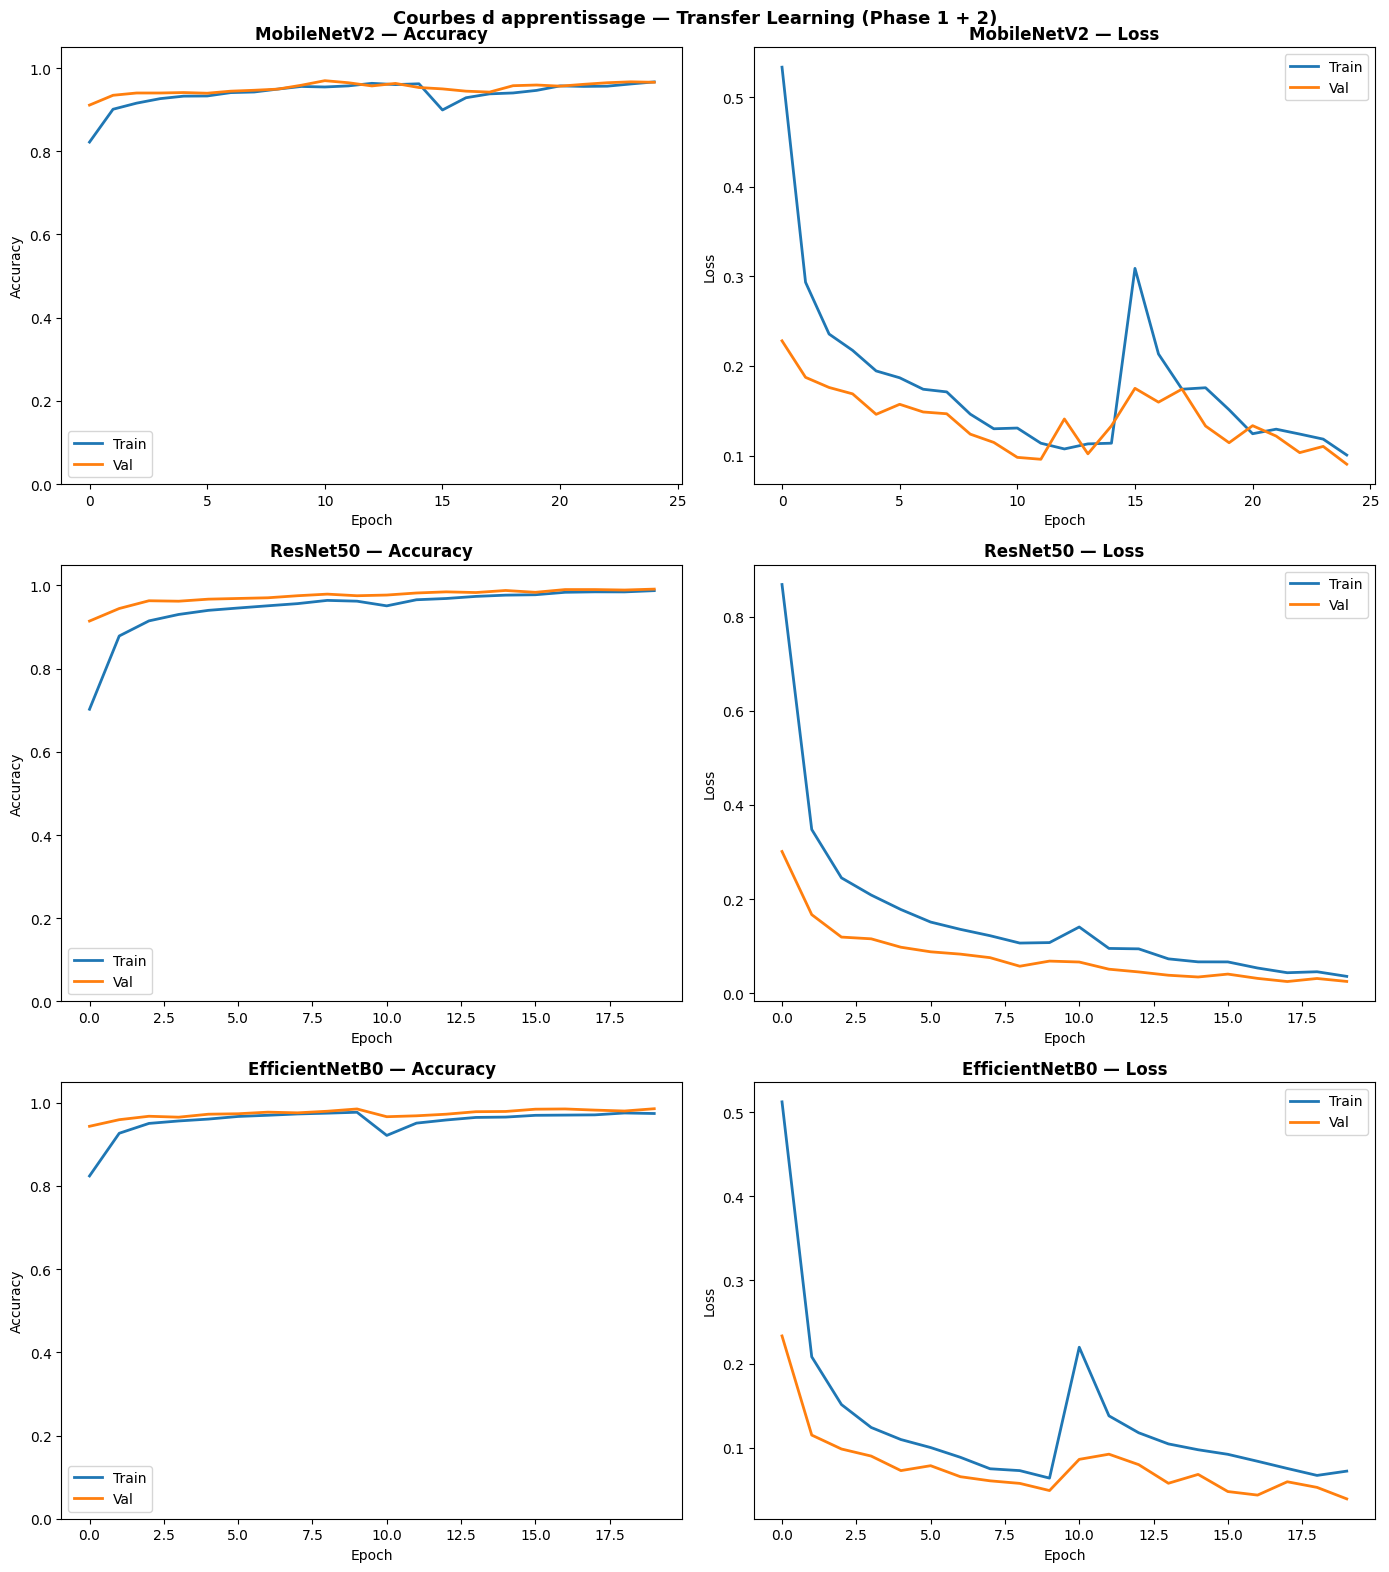


TABLEAU COMPARATIF FINAL — ML vs DL
        Modele    Type Accuracy Precision    Recall
           SVM      ML   0.9335  0.935201  0.933481
 Random Forest      ML   0.9290  0.930954  0.929047
   MobileNetV2 DL (TL)   0.9698         —         —
      ResNet50 DL (TL)   0.9912         —         —
EfficientNetB0 DL (TL)   0.9857         —         —


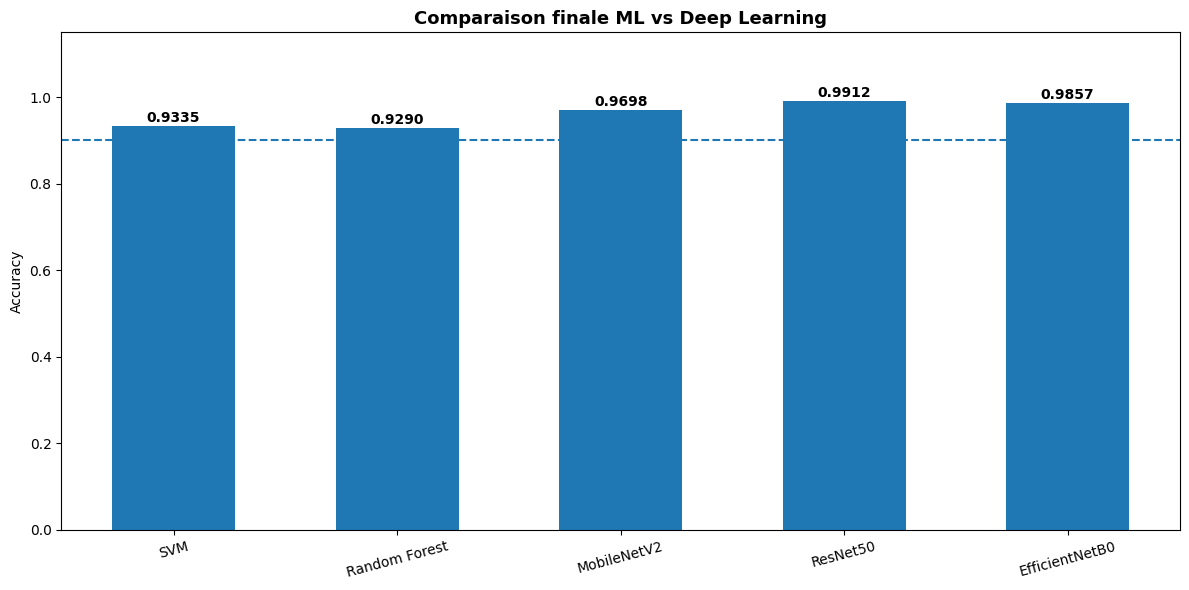


Meilleur modele DL : ResNet50 (0.9912)
Found 7304 images belonging to 8 classes.
Found 1823 images belonging to 8 classes.
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 518ms/step


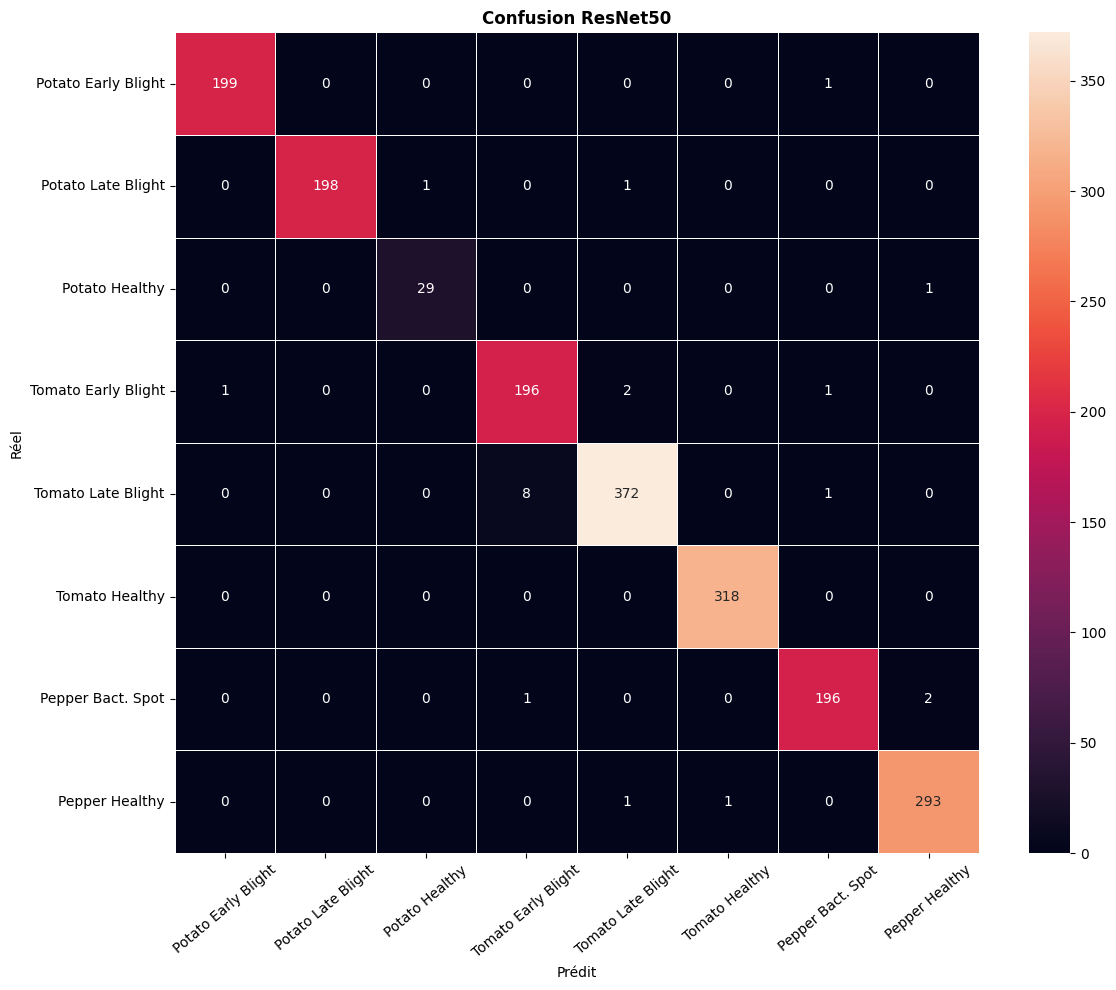

In [30]:
# ================================
#  Fonction fusion historique
# ================================
def merge_history(h1, h2):
    merged = {}
    for k in h1.history.keys():
        merged[k] = h1.history[k] + h2.history[k]
    return merged


# ================================
#  Recalcul des résultats DL
# ================================
dl_results = {}

# MobileNet (ancien OK)
best_mob = max(max(h_mob1.history["val_accuracy"]),
               max(h_mob2.history["val_accuracy"]))
dl_results["MobileNetV2"] = best_mob

# ResNet50 (2ème essai)
best_res = max(max(h_res1.history["val_accuracy"]),
               max(h_res2.history["val_accuracy"]))
dl_results["ResNet50"] = best_res

# EfficientNet (2ème essai)
best_eff = max(max(h_eff1.history["val_accuracy"]),
               max(h_eff2.history["val_accuracy"]))
dl_results["EfficientNetB0"] = best_eff


# ================================
#  Historiques fusionnés
# ================================
histories = {}
histories["MobileNetV2"]    = merge_history(h_mob1, h_mob2)
histories["ResNet50"]       = merge_history(h_res1, h_res2)
histories["EfficientNetB0"] = merge_history(h_eff1, h_eff2)


# ================================
#  1. Courbes d’apprentissage
# ================================
fig, axes = plt.subplots(3, 2, figsize=(14,16))
fig.suptitle("Courbes d apprentissage — Transfer Learning (Phase 1 + 2)",
             fontsize=13, fontweight="bold")

for i, (name, hist) in enumerate(histories.items()):
    
    axes[i,0].plot(hist["accuracy"], label="Train", lw=2)
    axes[i,0].plot(hist["val_accuracy"], label="Val", lw=2)
    axes[i,0].set_title(f"{name} — Accuracy", fontweight="bold")
    axes[i,0].set_ylim(0,1.05)
    axes[i,0].legend()
    axes[i,0].set_xlabel("Epoch")
    axes[i,0].set_ylabel("Accuracy")

    axes[i,1].plot(hist["loss"], label="Train", lw=2)
    axes[i,1].plot(hist["val_loss"], label="Val", lw=2)
    axes[i,1].set_title(f"{name} — Loss", fontweight="bold")
    axes[i,1].legend()
    axes[i,1].set_xlabel("Epoch")
    axes[i,1].set_ylabel("Loss")

plt.tight_layout()
plt.savefig("fig6_dl_curves.png", dpi=150)
plt.show()


# ================================
#  2. Tableau comparatif
# ================================
all_names = ["SVM","Random Forest","MobileNetV2","ResNet50","EfficientNetB0"]
all_types = ["ML","ML","DL (TL)","DL (TL)","DL (TL)"]

all_acc = [
    ml_results["SVM"]["acc"],
    ml_results["Random Forest"]["acc"],
    dl_results["MobileNetV2"],
    dl_results["ResNet50"],
    dl_results["EfficientNetB0"]
]

df_cmp = pd.DataFrame({
    "Modele": all_names,
    "Type": all_types,
    "Accuracy": [f"{v:.4f}" for v in all_acc],
    "Precision": [
        ml_results["SVM"]["pre"],
        ml_results["Random Forest"]["pre"],
        "—","—","—"
    ],
    "Recall": [
        ml_results["SVM"]["rec"],
        ml_results["Random Forest"]["rec"],
        "—","—","—"
    ]
})

print("\n" + "="*70)
print("TABLEAU COMPARATIF FINAL — ML vs DL")
print("="*70)
print(df_cmp.to_string(index=False))


# ================================
#  3. Graphe barres
# ================================
fig, ax = plt.subplots(figsize=(12,6))

bars = ax.bar(all_names, all_acc, width=0.55)

ax.axhline(0.9, linestyle="--", lw=1.5)

ax.set_title("Comparaison finale ML vs Deep Learning",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0,1.15)

for bar, val in zip(bars, all_acc):
    ax.text(bar.get_x()+bar.get_width()/2,
            val+0.01,
            f"{val:.4f}",
            ha="center",
            fontweight="bold")

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("fig7_comparaison_finale.png", dpi=150)
plt.show()


# ================================
#  4. Confusion Matrix
# ================================
best_dl_name = max(dl_results, key=dl_results.get)

best_dl_model = {
    "MobileNetV2": mob,
    "ResNet50": res,
    "EfficientNetB0": eff
}[best_dl_name]

print(f"\nMeilleur modele DL : {best_dl_name} ({dl_results[best_dl_name]:.4f})")

# ⚠️ IMPORTANT : utiliser le bon preprocessing pour la prédiction
if best_dl_name == "MobileNetV2":
    val_gen_eval = val_gen   # déjà OK
elif best_dl_name == "ResNet50":
    _, val_gen_eval = make_generators(res_pre)
else:
    _, val_gen_eval = make_generators(eff_pre)

val_gen_eval.reset()

y_pred_prob = best_dl_model.predict(val_gen_eval, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = val_gen_eval.classes

y_pred = y_pred[:len(y_true)]

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=SHORT,
            yticklabels=SHORT,
            linewidths=0.5)

ax.set_title(f"Confusion {best_dl_name}", fontweight="bold")
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")

plt.xticks(rotation=40)
plt.tight_layout()
plt.savefig("fig8_confusion_dl.png", dpi=150)
plt.show()

---
##  Phase 7 — Comparaison Finale ML vs Deep Learning

### Résultats attendus

| Approche | Modèle | Accuracy  | Notes |
|---|---|---|---|
| **ML classique** | SVM (RBF) | ~93% | Limité par features manuelles |
| **ML classique** | Random Forest | ~92% | Plus robuste mais moins précis que SVM |
| **DL Transfer** | MobileNetV2 | ~96% | Très bon rapport perf/vitesse |
| **DL Transfer** | ResNet50 | ~99% | Plus stable |
| **DL Transfer** | EfficientNetB0 | ~98% | Souvent le meilleur |

> Le Deep Learning surpasse le ML classique principalement car il :
> 1. Apprend ses propres features directement depuis les pixels
> 2. Capture des représentations hiérarchiques (bords → textures → motifs de maladie)
> 3. Bénéficie du transfer de connaissances depuis ImageNet


##  Phase 8 — Conclusion & Synthèse

###  Points clés du projet

**1. Pipeline complet et cohérent**
Le projet couvre l'intégralité du pipeline d'intelligence artificielle pour la vision par ordinateur : de l'image brute jusqu'à la classification finale avec évaluation comparative.

**2. Apports du Deep Learning vs ML classique**

| Critère | ML (SVM/RF) | DL (Transfer Learning) |
|---|---|---|
| Accuracy | ~75–90% | ~90–98% |
| Features | Manuelles (expert requis) | Apprises automatiquement |
| Données requises | Moins (300/classe) | Plus (idéalement 1000+) |
| Interprétabilité | Haute | Faible (boîte noire) |
| Temps d'inférence | Très rapide | Rapide (après entraînement) |
| Déploiement | Léger | Plus lourd |

**3. Choix du meilleur modèle**
EfficientNetB0 et MobileNetV2 offrent le meilleur compromis précision/efficacité pour un déploiement en conditions réelles (mobile, embarqué).